# Generative Adversarial Networks (GAN)

A VAE generates by maximizing a likelihood, which tends to give blurry images. A **GAN** takes a different route: two networks play a game.

- **Generator G**: turns random noise `z` into a fake image
- **Discriminator D**: looks at an image and outputs the probability it is real

G is trained to fool D; D is trained to catch G. As D gets better at spotting fakes, G is forced to make them more realistic. There is no reconstruction loss and no explicit likelihood.

Covered here: the two-player training loop, the loss functions, what to watch while training, and why GANs are famously finicky. MNIST, MLP networks, about a minute on CPU/MPS.

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'

# GAN generators usually end in tanh, so scale real images to [-1, 1] to match
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_ds = datasets.MNIST('./data', train=True, download=True, transform=tf)
loader = DataLoader(train_ds, batch_size=128, shuffle=True, drop_last=True)
Z_DIM = 64

def show(imgs, n=10, title=''):
    imgs = (imgs[:n].detach().cpu().view(-1, 28, 28) + 1) / 2          # back to [0,1]
    fig, ax = plt.subplots(1, n, figsize=(n, 1.2))
    for a, im in zip(ax, imgs): a.imshow(im, cmap='gray', vmin=0, vmax=1); a.axis('off')
    fig.suptitle(title, y=1.05); plt.show()
print('device:', DEVICE)

device: mps


## 1. The two networks

`D` is a binary classifier (real vs fake) that outputs a **logit**. `G` maps `z ~ N(0, I)` to a 784-pixel image. LeakyReLU in D (not ReLU) keeps gradients alive for negative inputs, a standard GAN choice.

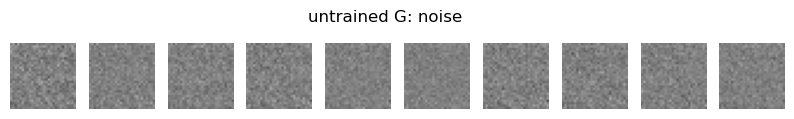

In [2]:
G = nn.Sequential(
    nn.Linear(Z_DIM, 256), nn.ReLU(),
    nn.Linear(256, 512),   nn.ReLU(),
    nn.Linear(512, 784),   nn.Tanh()).to(DEVICE)

D = nn.Sequential(
    nn.Linear(784, 512), nn.LeakyReLU(0.2),
    nn.Linear(512, 256), nn.LeakyReLU(0.2),
    nn.Linear(256, 1)).to(DEVICE)                        # logit, no sigmoid (BCEWithLogits)

fixed_z = torch.randn(10, Z_DIM, device=DEVICE)          # same noise every epoch -> watch G improve
with torch.no_grad(): show(G(fixed_z), title='untrained G: noise')

## 2. The losses

With `BCEWithLogitsLoss`:

- **D step:** real images labelled 1, fake labelled 0. Minimize `BCE(D(real), 1) + BCE(D(G(z)), 0)`.
- **G step:** wants D to say "real" for fakes. Minimize `BCE(D(G(z)), 1)`.

The G loss uses label **1** for fakes ("non-saturating" loss). The original formulation minimizes `log(1 - D(G(z)))`, which has almost no gradient exactly when G is bad and D is confident, the moment G most needs a signal.

### Two details that are easy to get wrong
- In the D step, call `G(z).detach()` so D's loss does not backpropagate into G.
- In the G step, the fakes go through D *without* detach; gradients flow through D into G. Only `opt_G` steps, so D's weights stay put.

In [3]:
opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # beta1=0.5: standard GAN setting
opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()

hist = {'d': [], 'g': [], 'd_real': [], 'd_fake': []}
snapshots = {}

for epoch in range(1, 21):
    for real, _ in loader:
        real = real.view(-1, 784).to(DEVICE); B = len(real)
        ones, zeros = torch.ones(B, 1, device=DEVICE), torch.zeros(B, 1, device=DEVICE)

        # --- D step ---
        fake = G(torch.randn(B, Z_DIM, device=DEVICE)).detach()
        d_real, d_fake = D(real), D(fake)
        loss_d = bce(d_real, ones) + bce(d_fake, zeros)
        opt_D.zero_grad(); loss_d.backward(); opt_D.step()

        # --- G step ---
        d_out = D(G(torch.randn(B, Z_DIM, device=DEVICE)))
        loss_g = bce(d_out, ones)                         # fool D: label fakes as real
        opt_G.zero_grad(); loss_g.backward(); opt_G.step()

    hist['d'].append(loss_d.item()); hist['g'].append(loss_g.item())
    hist['d_real'].append(torch.sigmoid(d_real).mean().item())
    hist['d_fake'].append(torch.sigmoid(d_fake).mean().item())
    if epoch in (1, 5, 20):
        with torch.no_grad(): snapshots[epoch] = G(fixed_z).cpu()
    if epoch % 4 == 0 or epoch == 1:
        print(f'epoch {epoch:2d}  D loss {hist["d"][-1]:.3f}  G loss {hist["g"][-1]:.3f}  '
              f'D(real)={hist["d_real"][-1]:.2f}  D(fake)={hist["d_fake"][-1]:.2f}')

epoch  1  D loss 0.597  G loss 2.133  D(real)=0.67  D(fake)=0.10


epoch  4  D loss 0.571  G loss 1.373  D(real)=0.77  D(fake)=0.14


epoch  8  D loss 0.278  G loss 4.630  D(real)=0.96  D(fake)=0.17


epoch 12  D loss 0.346  G loss 2.471  D(real)=0.84  D(fake)=0.05


epoch 16  D loss 0.653  G loss 2.594  D(real)=0.88  D(fake)=0.33


epoch 20  D loss 0.699  G loss 1.616  D(real)=0.74  D(fake)=0.23


## 3. Progress on fixed noise

Same 10 noise vectors every time, so differences are due to G improving, not different inputs.

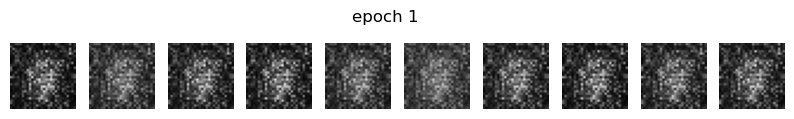

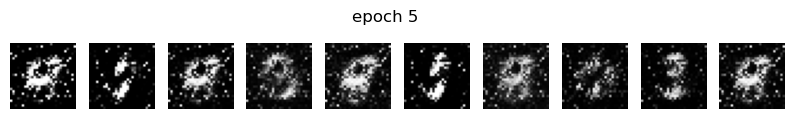

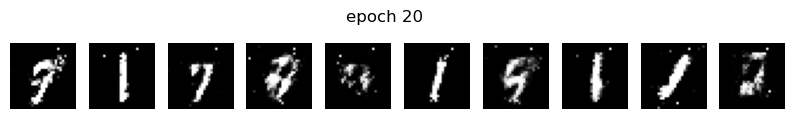

In [4]:
for ep, imgs in snapshots.items(): show(imgs, title=f'epoch {ep}')

## 4. Reading the training curves

Unlike every other notebook here, **the loss is not a progress bar.** Both networks improve together, so both losses can stay roughly flat while the images get better. Watch these instead:

- `D(real)` and `D(fake)`: the probabilities D assigns. A healthy game hovers with D(real) high and D(fake) low but *not* extreme. Both near 0.5 means D is guessing.
- **D loss to ~0**: D has won; G gets no useful gradient and stops learning.
- **G loss climbing steadily while D loss falls**: same story.
- **Looking at samples** is the real metric. (Quantitative scores like FID exist but need a pretrained Inception network.)

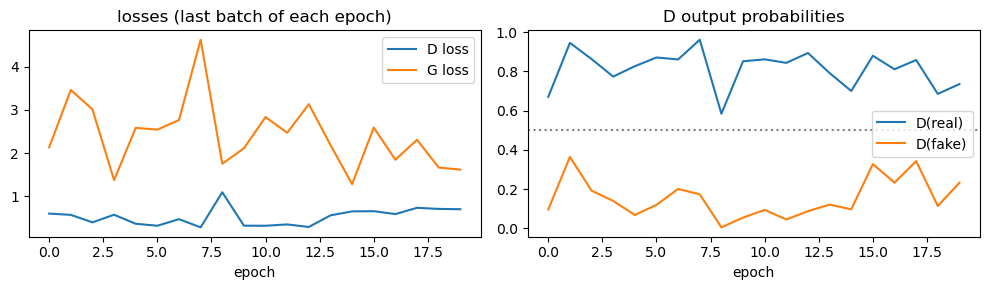

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist['d'], label='D loss'); ax[0].plot(hist['g'], label='G loss'); ax[0].legend(); ax[0].set_xlabel('epoch'); ax[0].set_title('losses (last batch of each epoch)')
ax[1].plot(hist['d_real'], label='D(real)'); ax[1].plot(hist['d_fake'], label='D(fake)'); ax[1].axhline(.5, ls=':', c='gray')
ax[1].legend(); ax[1].set_xlabel('epoch'); ax[1].set_title('D output probabilities'); plt.tight_layout(); plt.show()

## 5. Generate and interpolate

New samples are just `G(torch.randn(...))`. Interpolating between two noise vectors shows G learned a smooth map.

**Honest read of the result:** after 20 epochs the strokes are crisp (no VAE-style blur) but many samples are malformed or ambiguous, and the interpolation moves between digits in fairly abrupt steps. A small MLP GAN trained for a minute is a working demonstration, not a good generator; a DCGAN and more epochs (exercise 1) improve it a lot.

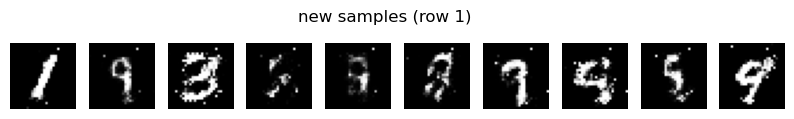

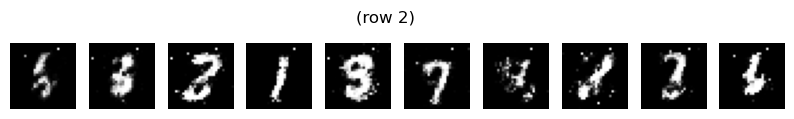

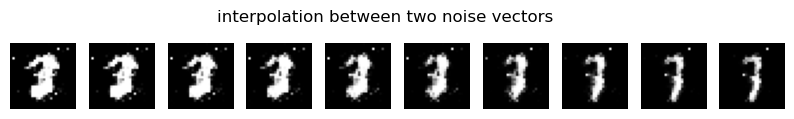

In [6]:
G.eval()
with torch.no_grad():
    show(G(torch.randn(10, Z_DIM, device=DEVICE)), title='new samples (row 1)')
    show(G(torch.randn(10, Z_DIM, device=DEVICE)), title='(row 2)')
    za, zb = torch.randn(1, Z_DIM, device=DEVICE), torch.randn(1, Z_DIM, device=DEVICE)
    t = torch.linspace(0, 1, 10, device=DEVICE)[:, None]
    show(G(za * (1 - t) + zb * t), title='interpolation between two noise vectors')

## 6. Why GANs are hard

| Failure | What you see | Typical fixes |
|---|---|---|
| **D overpowers G** | D loss -> 0, G loss grows, samples stop improving | weaken D, label smoothing, add noise to D inputs, lower D lr |
| **Mode collapse** | G produces only a few distinct outputs, ignoring the rest of the data | minibatch discrimination, Wasserstein loss, unrolled GANs |
| **Oscillation / instability** | losses and samples swing wildly | `betas=(0.5, 0.999)`, spectral norm, gradient penalty |
| **No good progress metric** | loss is uninformative | look at samples; FID / Inception Score |

To check for mode collapse here: do the 20 samples above show a mix of digits, or the same two or three shapes repeated?

## 7. Comparison

| | VAE | GAN |
|---|---|---|
| Training | one loss, stable | two-player game, finicky |
| Sample sharpness | blurrier | crisper edges (but can be malformed, as above) |
| Latent space | explicit, encoder included | no encoder; cannot encode a real image directly |
| Covers all modes | yes (likelihood-based) | not guaranteed (mode collapse) |
| Loss tracks quality | yes (ELBO) | no |

Both have largely been overtaken by **diffusion models** for image generation, but the ideas here (latent spaces, adversarial training, learning a data distribution) carry over.

## Exercises
1. Swap the MLPs for a DCGAN: `ConvTranspose2d` in G, `Conv2d` stride-2 in D, BatchNorm. Samples sharpen noticeably.
2. Make D too strong (4 D steps per G step, or lr 10x higher) and watch the failure from the table.
3. Add one-sided label smoothing: use 0.9 instead of 1 for real labels in the D step.
4. Make a conditional GAN: concatenate a one-hot digit to `z` in G and to the image in D, then generate a chosen digit.